In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("SafariLink EDA environment is ready!")

SafariLink EDA environment is ready!


In [2]:
# Load cleaned datasets
bookings = pd.read_csv("../data/processed/bookings_clean.csv")
customers = pd.read_csv("../data/processed/customers_clean.csv")


In [ ]:
# Prepare dates- convert date to proper date standard format

bookings["date"] = pd.to_datetime(bookings["date"])
customers["signup_date"] = pd.to_datetime(customers["signup_date"])

print("Bookings:", bookings.shape)
print("Customers:", customers.shape)
print("Date range:", bookings["date"].min(), "to", bookings["date"].max())

display(bookings.head())

Bookings: (690708, 39)
Customers: (6000, 7)
Date range: 2023-01-01 00:00:00 to 2026-09-30 00:00:00


,booking_id,date,route_id,promo,fare,payment,seats,branch_id,customer_id,is_guest,...,base_fare,seats_per_bus,trips_per_day,service_class,daily_seat_capacity,base_daily_bookings,branch,county,region,route
0,1,2023-01-01,1,False,1450.0,cash,2,1,2874.0,False,...,1500,49,3,Executive,147,45.9375,Nairobi,Nairobi,Nairobi,Nairobi - Mombasa
1,2,2023-01-01,1,False,1470.0,mpesa,1,1,3374.0,False,...,1500,49,3,Executive,147,45.9375,Nairobi,Nairobi,Nairobi,Nairobi - Mombasa
2,3,2023-01-01,1,False,1460.0,cash,2,1,5751.0,False,...,1500,49,3,Executive,147,45.9375,Nairobi,Nairobi,Nairobi,Nairobi - Mombasa
3,4,2023-01-01,1,False,1490.0,mpesa,2,1,4912.0,False,...,1500,49,3,Executive,147,45.9375,Nairobi,Nairobi,Nairobi,Nairobi - Mombasa
4,5,2023-01-01,1,False,1540.0,mpesa,1,1,4126.0,False,...,1500,49,3,Executive,147,45.9375,Nairobi,Nairobi,Nairobi,Nairobi - Mombasa


In [4]:
# 2 — Revenue by route . This identifies which routes generate the most calculated revenue.

route_performance = (
    bookings.groupby("route", as_index=False)
    .agg(
        total_revenue=("revenue", "sum"),
        total_bookings=("booking_id", "nunique"),
        tickets_sold=("seats", "sum")
    )
    .sort_values("total_revenue", ascending=False)
)

route_performance["total_revenue"] = route_performance["total_revenue"].round(2)

display(route_performance)


,route,total_revenue,total_bookings,tickets_sold
8,Nairobi - Mombasa,239537810.0,88677,144084
2,Mombasa - Nairobi,239027100.0,88251,143314
6,Nairobi - Kisumu,223701180.0,88875,144061
5,Nairobi - Kisii,139616560.0,59605,96829
3,Nairobi - Eldoret,127403320.0,59047,95840
9,Nairobi - Nakuru,112244780.0,89003,144538
10,Nairobi - Nyeri,95877320.0,88851,143865
7,Nairobi - Malindi,95532510.0,29515,47995
1,Mombasa - Malindi,57475530.0,39953,64788
4,Nairobi - Garissa,56553380.0,19734,31975


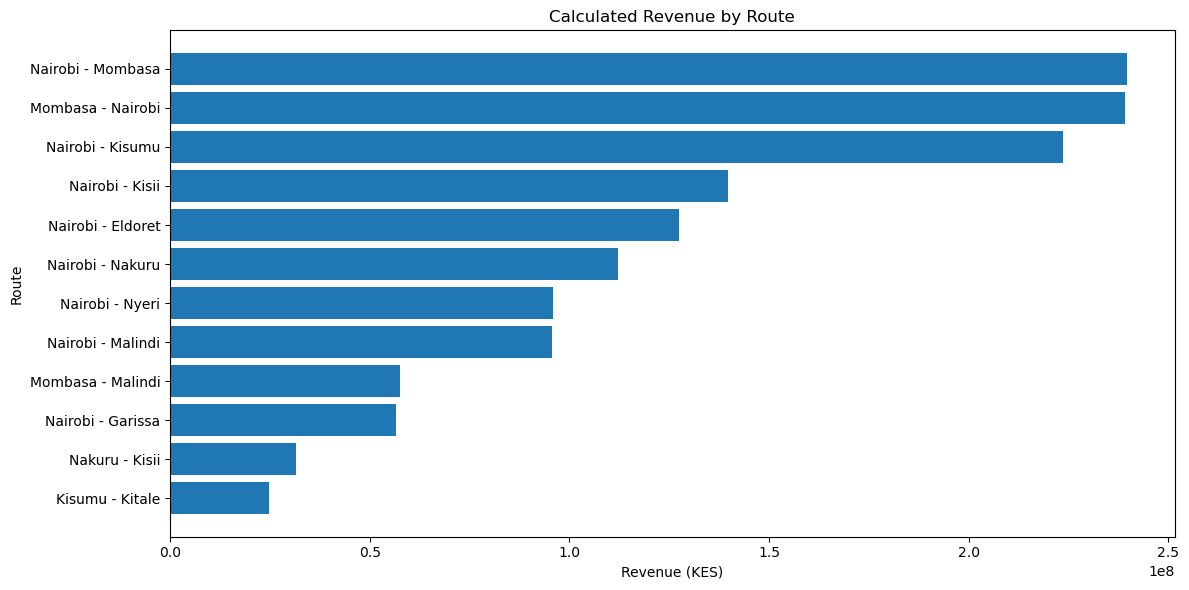

In [5]:
# 3 — Visualise route revenue

plt.figure(figsize=(12, 6))

plt.barh(
    route_performance["route"],
    route_performance["total_revenue"]
)

plt.gca().invert_yaxis()
plt.title("Calculated Revenue by Route")
plt.xlabel("Revenue (KES)")
plt.ylabel("Route")
plt.tight_layout()
plt.show()


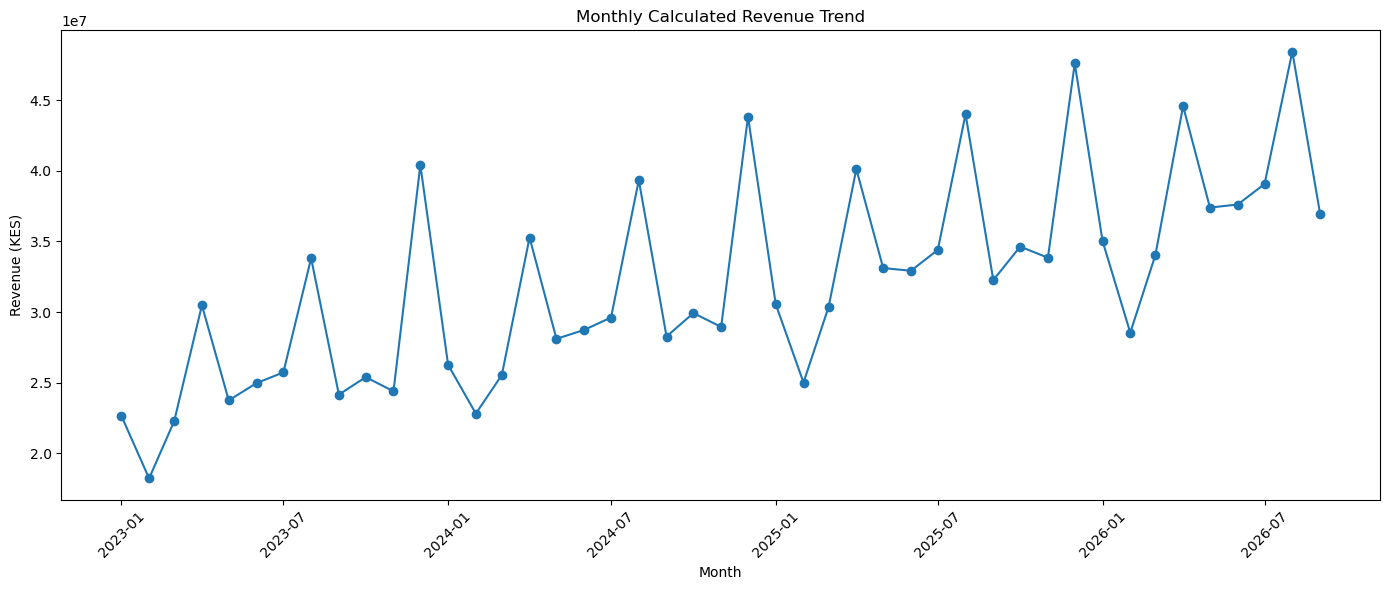

,year_month,total_bookings,total_revenue,tickets_sold,month_date
0,2023-01,12267,22654040.0,19631,2023-01-01
1,2023-02,9948,18214270.0,15765,2023-02-01
2,2023-03,11930,22261090.0,19277,2023-03-01
3,2023-04,16265,30475370.0,26019,2023-04-01
4,2023-05,12529,23740720.0,20093,2023-05-01


In [7]:
# 4 — Monthly booking and revenue trends

monthly_performance = (
    bookings.groupby("year_month", as_index=False)
    .agg(
        total_bookings=("booking_id", "nunique"),
        total_revenue=("revenue", "sum"),
        tickets_sold=("seats", "sum")
    )
)

monthly_performance["month_date"] = pd.to_datetime(
    monthly_performance["year_month"] + "-01"
)

monthly_performance = monthly_performance.sort_values("month_date")

plt.figure(figsize=(14, 6))
plt.plot(
    monthly_performance["month_date"],
    monthly_performance["total_revenue"],
    marker="o"
)

plt.title("Monthly Calculated Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (KES)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(monthly_performance.head())


In [ ]:
display(monthly_performance)

In [ ]:
# performance by calendar month across all years
#  totals for each individual month
monthly_totals = (
    bookings.assign(
        year_month=bookings["date"].dt.to_period("M").astype(str),
        calendar_month=bookings["date"].dt.month
    )
    .groupby(["year_month", "calendar_month"], as_index=False)
    .agg(
        total_revenue=("revenue", "sum"),
        total_bookings=("booking_id", "nunique"),
        tickets_sold=("seats", "sum")
    )


# average performance for each calendar month
monthly_patterns = (
    monthly_totals.groupby("calendar_month")
    .agg(
        average_revenue=("total_revenue", "mean"),
        average_bookings=("total_bookings", "mean"),
        average_tickets=("tickets_sold", "mean")
    )
    .reset_index()
)

monthly_patterns["month_name"] = (
    monthly_patterns["calendar_month"].map(month_names)
)

monthly_patterns = monthly_patterns.sort_values(
    "average_revenue", ascending=False
)

display(monthly_patterns.round(2))


,calendar_month,average_revenue,average_bookings,average_tickets,month_name
11,12,43956250.0,20970.67,33972.67,December
7,8,41402850.0,19516.00,31689.75,August
3,4,37616477.5,18058.25,29301.00,April
6,7,32200735.0,15287.50,24828.25,July
5,6,31058075.0,14801.50,24068.50,June
4,5,30588487.5,14534.75,23643.50,May
8,9,30411425.0,14283.50,23203.50,September
9,10,29981860.0,14416.00,23374.00,October
10,11,29058550.0,14028.67,22709.33,November
0,1,28624435.0,14008.75,22708.00,January


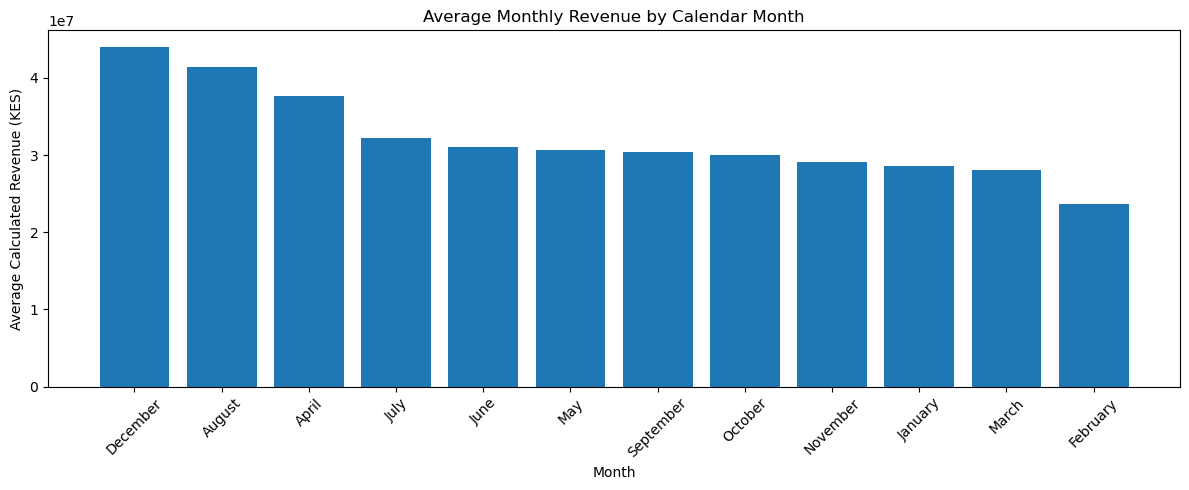

In [11]:

plt.figure(figsize=(12, 5))

plt.bar(
    monthly_patterns["month_name"],
    monthly_patterns["average_revenue"]
)

plt.title("Average Monthly Revenue by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average Calculated Revenue (KES)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [12]:

#5 Compare annual performance

bookings["year"] = bookings["date"].dt.year

annual_summary = (
    bookings.groupby("year", as_index=False)
    .agg(
        total_revenue=("revenue", "sum"),
        total_bookings=("booking_id", "nunique"),
        tickets_sold=("seats", "sum")
    )
)

annual_summary["revenue_per_ticket"] = (
    annual_summary["total_revenue"] /
    annual_summary["tickets_sold"]
)

display(annual_summary.round(2))


,year,total_revenue,total_bookings,tickets_sold,revenue_per_ticket
0,2023,316182830.0,165850,266365,1187.03
1,2024,366636870.0,180582,291840,1256.29
2,2025,418831360.0,193866,316156,1324.76
3,2026,341679280.0,150410,246478,1386.25


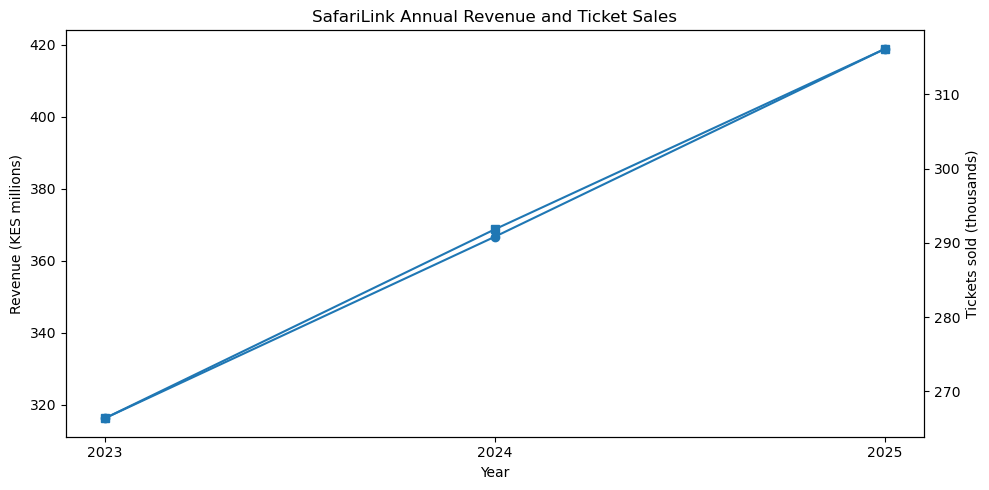

In [13]:

# Annual trends visuals - 2026 is excluded from the full-year comparison because the data runs upto september
full_years = annual_summary[annual_summary["year"] < 2026]

fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.plot(
    full_years["year"],
    full_years["total_revenue"] / 1_000_000,
    marker="o",
    label="Revenue (KES millions)"
)
ax1.set_xlabel("Year")
ax1.set_ylabel("Revenue (KES millions)")
ax1.set_title("SafariLink Annual Revenue and Ticket Sales")
ax1.set_xticks(full_years["year"])

ax2 = ax1.twinx()
ax2.plot(
    full_years["year"],
    full_years["tickets_sold"] / 1_000,
    marker="s",
    label="Tickets sold (thousands)"
)
ax2.set_ylabel("Tickets sold (thousands)")

fig.tight_layout()
plt.show()


In [14]:
#5 Customer retention analysis
print("Customer columns:")
print(customers.columns.tolist())

print("\nCustomer dataset shape:")
print(customers.shape)

display(customers.head())


Customer columns:
['customer_id', 'segment', 'home_branch_id', 'signup_date', 'churn_date', 'churned', 'tenure_days']

Customer dataset shape:
(6000, 7)


,customer_id,segment,home_branch_id,signup_date,churn_date,churned,tenure_days
0,1,occasional,1,2024-11-10,NaN,False,689
1,2,occasional,3,2023-01-01,NaN,False,1368
2,3,occasional,2,2023-04-07,NaN,False,1272
3,4,occasional,4,2023-01-01,2024-06-14,True,530
4,5,commuter,1,2023-01-01,NaN,False,1368


In [ ]:

# total number of customers
total_customers = customers["customer_id"].nunique()

# customers marked as churned
churned_customers = customers.loc[
    customers["churned"] == True, "customer_id"
].nunique()

#  recorded churn rate
churn_rate = (churned_customers / total_customers) * 100

print("CUSTOMER OVERVIEW")
print("-----------------")
print(f"Total customers: {total_customers:,}")
print(f"Customers marked as churned: {churned_customers:,}")
print(f"Customers not marked as churned: {total_customers - churned_customers:,}")
print(f"Recorded churn rate: {churn_rate:.2f}%")


CUSTOMER OVERVIEW
-----------------
Total customers: 6,000
Customers marked as churned: 1,674
Customers not marked as churned: 4,326
Recorded churn rate: 27.90%


In [17]:

# Summarise customers by segment
segment_summary = (
    customers.groupby("segment")
    .agg(
        total_customers=("customer_id", "nunique"),
        churned_customers=("churned", "sum")
    )
    .reset_index()
)

# Calculate churn percentage for each segment
segment_summary["churn_rate_pct"] = (
    segment_summary["churned_customers"]
    / segment_summary["total_customers"] * 100
)

# Show the segments with the highest recorded churn first
segment_summary = segment_summary.sort_values(
    "churn_rate_pct", ascending=False
)

display(segment_summary.round(2))


,segment,total_customers,churned_customers,churn_rate_pct
2,occasional,3564,1029,28.87
0,business,887,236,26.61
1,commuter,1549,409,26.40


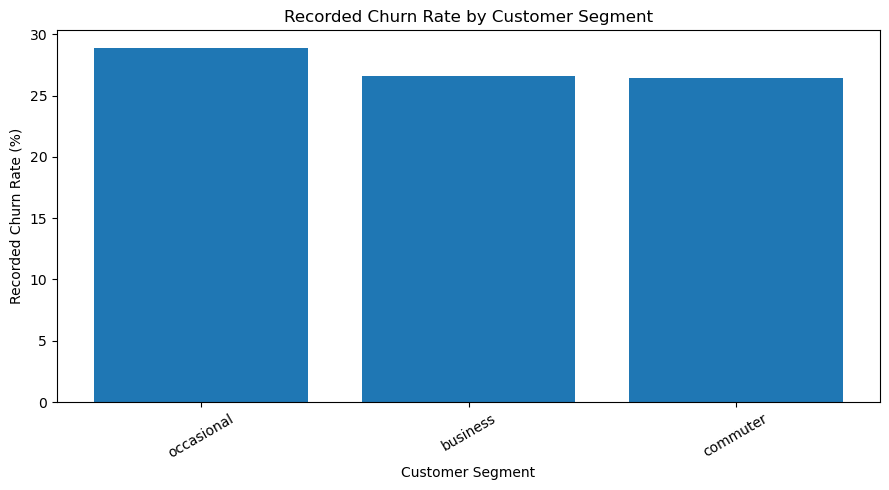

In [18]:

plt.figure(figsize=(9, 5))

plt.bar(
    segment_summary["segment"],
    segment_summary["churn_rate_pct"]
)

plt.title("Recorded Churn Rate by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Recorded Churn Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [19]:

# check dates  format
bookings["date"] = pd.to_datetime(bookings["date"])

# Used the latest date in the dataset as the reference date
data_end_date = bookings["date"].max()
activity_start_date = data_end_date - pd.Timedelta(days=89)

# Find each customer's most recent booking
customer_activity = (
    bookings.dropna(subset=["customer_id"])
    .groupby("customer_id")
    .agg(last_booking_date=("date", "max"))
    .reset_index()
)

# Attach booking activity to the customer dataset
retention_check = customers.merge(
    customer_activity,
    on="customer_id",
    how="left"
)

# Identify customers with a booking in the last 90 days
retention_check["recent_booking"] = (
    retention_check["last_booking_date"].ge(activity_start_date)
    & retention_check["last_booking_date"].le(data_end_date)
)

print("Activity window:")
print(f"{activity_start_date.date()} to {data_end_date.date()}")

print("\nRecent booking activity:")
display(
    retention_check.groupby("churned", dropna=False)
    .agg(
        customers=("customer_id", "nunique"),
        customers_with_recent_booking=("recent_booking", "sum")
    )
    .reset_index()
)


Activity window:
2026-07-03 to 2026-09-30

Recent booking activity:


,churned,customers,customers_with_recent_booking
0,False,4326,4282
1,True,1674,72


In [20]:

# Find customers whose churn label and recent activity may conflict
possible_mismatches = retention_check[
    (
        (retention_check["churned"] == True)
        & (retention_check["recent_booking"] == True)
    )
    |
    (
        (retention_check["churned"] == False)
        & (retention_check["recent_booking"] == False)
    )
]

print("Customers to investigate:", len(possible_mismatches))

display(
    possible_mismatches[
        [
            "customer_id",
            "segment",
            "signup_date",
            "churn_date",
            "churned",
            "last_booking_date",
            "recent_booking"
        ]
    ].head(20)
)


Customers to investigate: 116


,customer_id,segment,signup_date,churn_date,churned,last_booking_date,recent_booking
69,70,occasional,2026-08-23,NaN,False,NaT,False
87,88,occasional,2026-08-26,NaN,False,NaT,False
182,183,occasional,2023-03-10,NaN,False,2026-06-06,False
205,206,commuter,2026-02-04,2026-08-14,True,2026-07-29,True
321,322,occasional,2025-07-11,NaN,False,2026-05-31,False
495,496,occasional,2023-01-01,NaN,False,2026-06-21,False
644,645,occasional,2025-09-12,2026-09-03,True,2026-08-21,True
661,662,occasional,2024-08-07,NaN,False,2026-06-29,False
690,691,business,2026-03-19,2026-09-08,True,2026-08-15,True
706,707,occasional,2024-06-08,NaN,False,2026-06-22,False


In [21]:

# Compare each customer's last booking with their churn date

churn_date_check = retention_check.dropna(
    subset=["churn_date", "last_booking_date"]
).copy()

churn_date_check["booking_on_or_after_churn"] = (
    churn_date_check["last_booking_date"]
    >= pd.to_datetime(churn_date_check["churn_date"])
)

print("Customers with both a churn date and a booking date:",
      len(churn_date_check))

print("\nLast booking on or after churn date:")
print(
    churn_date_check["booking_on_or_after_churn"]
    .value_counts()
)

display(
    churn_date_check[
        churn_date_check["booking_on_or_after_churn"]
    ][
        [
            "customer_id",
            "segment",
            "churn_date",
            "last_booking_date",
            "churned"
        ]
    ].head(15)
)


Customers with both a churn date and a booking date: 1589

Last booking on or after churn date:
booking_on_or_after_churn
False    1123
True      466
Name: count, dtype: int64


,customer_id,segment,churn_date,last_booking_date,churned
18,19,occasional,2023-06-25,2023-06-25,True
33,34,business,2023-09-28,2023-09-30,True
36,37,commuter,2025-08-30,2025-08-30,True
55,56,occasional,2024-07-18,2024-07-24,True
68,69,commuter,2026-05-27,2026-05-28,True
70,71,commuter,2023-01-21,2023-01-26,True
76,77,business,2026-04-15,2026-04-30,True
94,95,business,2023-01-25,2023-01-31,True
112,113,business,2026-06-18,2026-06-28,True
123,124,occasional,2025-04-20,2025-04-27,True


In [22]:
# Reload the latest cleaned files
bookings = pd.read_csv("../data/processed/bookings_clean.csv")
customers = pd.read_csv("../data/processed/customers_clean.csv")

# Convert dates to datetime format
bookings["date"] = pd.to_datetime(bookings["date"])
customers["signup_date"] = pd.to_datetime(customers["signup_date"])
customers["churn_date"] = pd.to_datetime(customers["churn_date"])

# Match bookings to customer dates
audit = bookings.merge(
    customers[["customer_id", "signup_date", "churn_date"]],
    on="customer_id",
    how="left"
)

# Count bookings that violate the customer dates
before_signup = (
    audit["customer_id"].notna()
    & (audit["date"] < audit["signup_date"])
)

after_churn = (
    audit["customer_id"].notna()
    & audit["churn_date"].notna()
    & (audit["date"] >= audit["churn_date"])
)

print("Bookings before signup:", int(before_signup.sum()))
print("Bookings on or after churn:", int(after_churn.sum()))

Bookings before signup: 2725
Bookings on or after churn: 1205


In [23]:
bookings = pd.read_csv("../data/processed/bookings_clean.csv")
customers = pd.read_csv("../data/processed/customers_clean.csv")

bookings["date"] = pd.to_datetime(bookings["date"])
customers["signup_date"] = pd.to_datetime(customers["signup_date"])
customers["churn_date"] = pd.to_datetime(customers["churn_date"])

print("Cleaned bookings:", len(bookings))
print("Customers:", len(customers))
print("Churned customers:", int(customers["churned"].sum()))

Cleaned bookings: 690708
Customers: 6000
Churned customers: 1674


In [24]:
# Overall customer churn rate
total_customers = len(customers)
churned_customers = int(customers["churned"].sum())
active_customers = total_customers - churned_customers

churn_rate = churned_customers / total_customers * 100

print("Total customers:", total_customers)
print("Churned customers:", churned_customers)
print("Not marked as churned:", active_customers)
print(f"Recorded churn rate: {churn_rate:.2f}%")

Total customers: 6000
Churned customers: 1674
Not marked as churned: 4326
Recorded churn rate: 27.90%


In [25]:
# Compare customer churn across segments
segment_churn = (
    customers.groupby("segment")
    .agg(
        total_customers=("customer_id", "count"),
        churned_customers=("churned", "sum")
    )
    .reset_index()
)

segment_churn["churn_rate_pct"] = (
    segment_churn["churned_customers"]
    / segment_churn["total_customers"] * 100
)

segment_churn = segment_churn.sort_values(
    "churn_rate_pct", ascending=False
)

display(segment_churn.round(2))

,segment,total_customers,churned_customers,churn_rate_pct
2,occasional,3564,1029,28.87
0,business,887,236,26.61
1,commuter,1549,409,26.40


In [26]:
#  holiday-related columns in the cleaned dataset
print([
    col for col in bookings.columns
    if "holiday" in col.lower()
])

['is_holiday', 'near_holiday']


In [27]:

# Compare bookings on and near holidays with other dates

holiday_summary = (
    bookings.groupby(["is_holiday", "near_holiday"])
    .agg(
        total_bookings=("booking_id", "count"),
        tickets_sold=("seats", "sum"),
        total_revenue=("revenue", "sum")
    )
    .reset_index()
)

display(holiday_summary.round(2))


,is_holiday,near_holiday,total_bookings,tickets_sold,total_revenue
0,False,False,609573,989294,1.273296e+09
1,False,True,66160,107223,1.386830e+08
2,True,True,14975,24322,3.135162e+07


In [28]:

# classification for easier interpretation

bookings["holiday_period"] = "Ordinary day"

bookings.loc[bookings["near_holiday"] == 1, "holiday_period"] = "Near holiday"
bookings.loc[bookings["is_holiday"] == 1, "holiday_period"] = "Holiday"

holiday_comparison = (
    bookings.groupby("holiday_period")
    .agg(
        total_bookings=("booking_id", "count"),
        tickets_sold=("seats", "sum"),
        total_revenue=("revenue", "sum"),
        average_fare=("fare", "mean")
    )
    .reset_index()
)

display(holiday_comparison.round(2))


,holiday_period,total_bookings,tickets_sold,total_revenue,average_fare
0,Holiday,14975,24322,3.135162e+07,1290.54
1,Near holiday,66160,107223,1.386830e+08,1291.45
2,Ordinary day,609573,989294,1.273296e+09,1286.35


In [30]:

# Display all column names in the bookings dataset
print(bookings.columns.tolist())


['booking_id', 'date', 'route_id', 'promo', 'fare', 'payment', 'seats', 'branch_id', 'customer_id', 'is_guest', 'fare_raw', 'fare_flag_corrected', 'flag_pre_signup', 'flag_post_churn', 'revenue', 'year', 'month', 'year_month', 'day_of_week', 'is_weekend', 'quarter', 'week', 'is_december', 'price_index', 'is_holiday', 'near_holiday', 'origin', 'destination', 'distance_km', 'base_fare', 'seats_per_bus', 'trips_per_day', 'service_class', 'daily_seat_capacity', 'base_daily_bookings', 'branch', 'county', 'region', 'route', 'holiday_period']


In [31]:

# Find columns whose names contain "payment"
print([
    col for col in bookings.columns
    if "payment" in col.lower() or "pay" in col.lower()
])


['payment']


In [32]:

# booking preferences by payment method

payment_summary = (
    bookings.groupby("payment")
    .agg(
        total_bookings=("booking_id", "count"),
        tickets_sold=("seats", "sum"),
        total_revenue=("revenue", "sum")
    )
    .reset_index()
    .sort_values("total_bookings", ascending=False)
)

payment_summary["booking_percentage"] = (
    payment_summary["total_bookings"]
    / payment_summary["total_bookings"].sum()
    * 100
)

display(payment_summary.round(2))


,payment,total_bookings,tickets_sold,total_revenue,booking_percentage
2,mpesa,504631,837607,1.084476e+09,73.06
1,cash,107296,161889,2.045404e+08,15.53
0,card,58160,87747,1.109164e+08,8.42
3,unknown,20621,33596,4.339750e+07,2.99


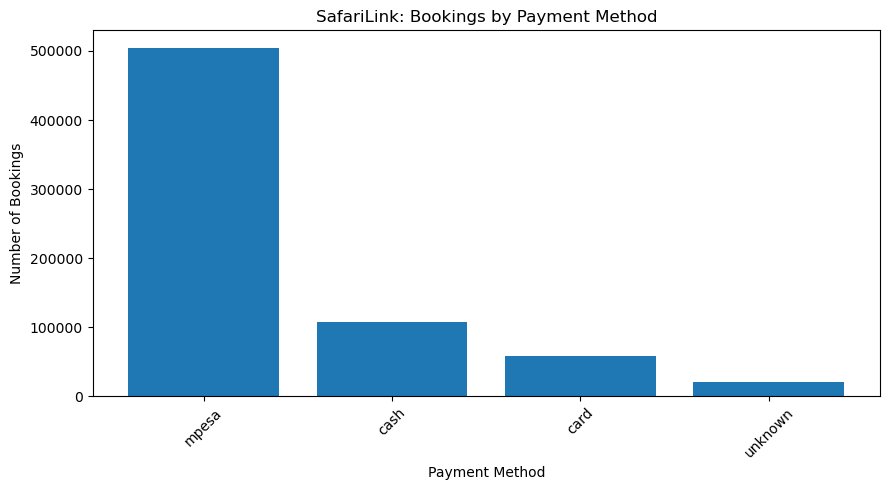

In [33]:
# preferences by payment method visual
plt.figure(figsize=(9, 5))

plt.bar(
    payment_summary["payment"].astype(str),
    payment_summary["total_bookings"]
)

plt.title("SafariLink: Bookings by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [34]:

# Compare average daily demand across holiday periods

daily_demand = (
    bookings.groupby(["date", "holiday_period"])
    .agg(
        bookings=("booking_id", "count"),
        tickets=("seats", "sum"),
        revenue=("revenue", "sum")
    )
    .reset_index()
)

daily_comparison = (
    daily_demand.groupby("holiday_period")
    .agg(
        number_of_days=("date", "nunique"),
        avg_daily_bookings=("bookings", "mean"),
        avg_daily_tickets=("tickets", "mean"),
        avg_daily_revenue=("revenue", "mean")
    )
    .reset_index()
)

display(daily_comparison.round(2))



,holiday_period,number_of_days,avg_daily_bookings,avg_daily_tickets,avg_daily_revenue
0,Holiday,24,623.96,1013.42,1306317.50
1,Near holiday,120,551.33,893.52,1155691.92
2,Ordinary day,1225,497.61,807.59,1039425.05
